# Aprendizado de Máquina – Introdução
## Sistema especialista com aprendizado supervisionado
**Profa. Kadidja Valéria**

**Inteligência Artificial e LFA | Sistemas Especialistas**

Execute este notebook no **Google Colab** ou no Jupyter, de cima para baixo. No Colab: Arquivo > Fazer upload de notebook > selecione este arquivo.

**Objetivo:** treinar um classificador e usar sua previsão como fato em um sistema especialista que recomenda atividades de estudo.

**Leitura:** [Guia IBM](https://www.ibm.com/br-pt/think/machine-learning) e [aprendizado supervisionado](https://www.ibm.com/br-pt/think/topics/supervised-learning).

## Responda: o que é aprendizado de máquina?

### O aprendizado de máquina (ML) é o subconjunto da inteligência artificial (IA) concentrado em algoritmos que podem "aprender" os padrões dos dados de treinamento e, posteriormente, fazer inferências precisas sobre novos dados. Essa capacidade de reconhecimento de padrões permite que os modelos de aprendizado de máquina tomem decisões ou previsões sem instruções explícitas e codificadas.





 ## O que são atributos e rótulos?
- Os atributos são informações que conseguimos dar ao modelo para que ele consiga  analisar e fazer uma previsãoOs
- Os rótulos são as respostas que o modelo precisa aprender a identificar. Usando o nosso projeto como exemplo, os atributos são textos padrão geralmente enviados por mensagem. (Mensagens de promoções reais ou não)




 ## Como classificação difere de regressão? Por que separar treino e teste?
 - De acordo com a IBM, a diferença entre classificação e regressão é que, enquanto a classificação prevê a categoria de um ponto de dados, a regressão prevê um valor numérico real associado. Tanto a classificação quanto a regressão são tipos de modelagem preditiva, mas com casos de uso distintos.
- Os modelos de classificação classificam os pontos de dados em categorias. Classificação é o processo de treinar um modelo de deep learning para descobrir a função que categoriza os pontos de dados.
- Os modelos de regressão consideram vários pontos de dados para prever um valor numérico contínuo para outra variável. Por exemplo, um modelo de regressão no ambiente de trabalho pode prever o salário de um trabalhador com base na idade, experiência, localização e educação.

## 1. Preparar o ambiente
No Colab, as bibliotecas geralmente já estão disponíveis. Se o próximo bloco apresentar `ModuleNotFoundError`, execute em uma nova célula: `%pip install pandas scikit-learn matplotlib` e tente novamente.

In [1]:
# Importação das bibliotecas necessárias
# pandas: manipulação e análise de dados estruturados
import pandas as pd
# matplotlib.pyplot: geração de gráficos e visualizações
import matplotlib.pyplot as plt
# train_test_split: divisão do dataset em conjuntos de treino e teste
from sklearn.model_selection import train_test_split
# CountVectorizer: transforma os textos das mensagens em contagens de palavras (números)
from sklearn.feature_extraction.text import CountVectorizer
# DecisionTreeClassifier: o algoritmo de árvore de decisão para classificação
# export_text e plot_tree: ferramentas para visualizar as regras aprendidas pela árvore
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree
# Métricas para avaliação do modelo: acurácia e matriz de confusão
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

# Confirmação de que as dependências foram carregadas com sucesso
print("Bibliotecas carregadas.")

Bibliotecas carregadas.


## 2. Dataset rotulado
Cada linha é um exemplo. As entradas são mensagens fictícias de spam. O rótulo 1 é para mensagens que são spam e o rótulo 0 para as que não são.

In [2]:
# Criação do DataFrame fictício com mensagens de spam e não spam
# Atributos (características): texto das mensagens (palavras como dinheiro, sorteio,
# cartão, prêmio, link, ganhou, grátis costumam aparecer nos spams)
# Rótulo (classe alvo): 1 = spam, 0 = não spam

mensagens_spam = [
    "Parabéns! Você ganhou um iPhone grátis. Clique aqui para receber.",
    "Ganhe R$ 5.000 por dia trabalhando apenas 10 minutos. Cadastre-se agora.",
    "Sua conta bancária será bloqueada. Clique no link para atualizar seus dados.",
    "Você foi selecionado para receber um prêmio de R$ 10.000. Resgate agora.",
    "Última oportunidade! Ganhe dinheiro fácil sem sair de casa.",
    "Seu cartão foi utilizado em uma compra suspeita. Confirme seus dados neste link.",
    "Você ganhou uma viagem internacional totalmente grátis. Clique para participar.",
    "Deposite R$ 50 e receba R$ 5.000 imediatamente.",
    "Parabéns! Você foi contemplado com um carro zero quilômetro.",
    "Sua senha expirou. Acesse este link para recuperar sua conta.",
    "Ganhe um celular novo respondendo a esta pesquisa.",
    "Oportunidade imperdível de investimento com retorno garantido de 500%.",
    "Seu pacote está retido. Pague a taxa pelo link para liberar a entrega.",
    "Você ganhou um vale compras de R$ 2.000. Resgate seu prêmio agora.",
    "Clique aqui e receba dinheiro gratuitamente na sua conta.",
    "Sua conta será encerrada hoje. Informe sua senha para evitar o bloqueio.",
    "Ganhe um salário de R$ 10.000 trabalhando cinco minutos por dia.",
    "Você foi escolhido para receber um prêmio exclusivo. Informe seu CPF.",
    "Aproveite esta promoção imperdível e garanta seu desconto clicando aqui.",
    "Seu cartão foi bloqueado. Confirme seus dados pessoais imediatamente.",
    "Fique rico rapidamente com nosso método secreto de investimento.",
    "Parabéns! Você ganhou um sorteio do qual nunca participou.",
    "Clique no link e informe seus dados para receber seu benefício.",
    "Aprenda Python e vire desenvolvedor sênior em apenas 3 dias. Ganhe R$ 20 mil.",
    "Última chance de ganhar um prêmio milionário. Responda agora!"
]

mensagens_nao_spam = [
    "Bom dia! Você poderia me enviar o arquivo da reunião?",
    "A reunião de amanhã foi marcada para as 14 horas.",
    "Olá, tudo bem? Vamos almoçar juntos hoje?",
    "Segue em anexo o relatório solicitado pela equipe.",
    "Sua consulta médica está agendada para segunda-feira.",
    "Não esqueça de estudar para a prova de programação.",
    "O professor disponibilizou uma nova atividade na plataforma.",
    "Seu pedido foi entregue com sucesso.",
    "Olá! Estou enviando o documento para sua avaliação.",
    "A equipe realizará uma reunião na próxima semana.",
    "Você pode confirmar sua presença no evento?",
    "Segue o comprovante do pagamento realizado.",
    "Sua inscrição no curso foi confirmada.",
    "Boa tarde! Podemos conversar sobre o projeto?",
    "O horário de atendimento será das 8 às 17 horas.",
    "Estou enviando as informações solicitadas por e-mail.",
    "Seu boleto está disponível no aplicativo oficial do banco.",
    "A atualização do sistema foi concluída com sucesso.",
    "Não se esqueça de entregar o trabalho até sexta-feira.",
    "Olá! Estou entrando em contato para confirmar nossa reunião.",
    "Seu cadastro no sistema foi realizado com sucesso.",
    "A apresentação do projeto acontecerá amanhã.",
    "O documento foi revisado e está pronto para aprovação.",
    "Recebi sua mensagem. Obrigado pelo contato!",
    "Sua compra foi aprovada. Consulte os detalhes no aplicativo oficial."
]

# Criação do DataFrame
dados = pd.DataFrame({
    "mensagem": mensagens_spam + mensagens_nao_spam,
    "rotulo": [1] * len(mensagens_spam) + [0] * len(mensagens_nao_spam)
})

# Exibição do dataset
print(dados.to_string(index=False))

# Exibição da distribuição de classes para verificar se o dataset está balanceado
print("\nQuantidade por classe:")
print(dados["rotulo"].value_counts())

                                                                        mensagem  rotulo
               Parabéns! Você ganhou um iPhone grátis. Clique aqui para receber.       1
        Ganhe R$ 5.000 por dia trabalhando apenas 10 minutos. Cadastre-se agora.       1
    Sua conta bancária será bloqueada. Clique no link para atualizar seus dados.       1
        Você foi selecionado para receber um prêmio de R$ 10.000. Resgate agora.       1
                     Última oportunidade! Ganhe dinheiro fácil sem sair de casa.       1
Seu cartão foi utilizado em uma compra suspeita. Confirme seus dados neste link.       1
 Você ganhou uma viagem internacional totalmente grátis. Clique para participar.       1
                                 Deposite R$ 50 e receba R$ 5.000 imediatamente.       1
                    Parabéns! Você foi contemplado com um carro zero quilômetro.       1
                   Sua senha expirou. Acesse este link para recuperar sua conta.       1
                     

## 3. Separar treinamento e teste
`X` contém os atributos (o texto das mensagens) e `y` contém o rótulo (1 = spam, 0 = não spam). Reservamos 37 exemplos de treino e 13 de teste. `stratify=y` preserva a proporção das classes nas duas partes; `random_state` torna a divisão reproduzível. O rótulo nunca entra em `X`.

In [3]:
X = dados["mensagem"]
y = dados["rotulo"]

X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y,
    test_size=0.25,
    stratify=y,
    random_state=42
)

print(len(X_treino), len(X_teste))  # 37 13

37 13


## 4. Treinar e avaliar
`fit` aprende padrões somente no treino; `predict` gera previsões. Acurácia é a fração de acertos no teste. Na matriz, linhas são classes reais e colunas são previstas. Não ajuste o modelo repetidamente para acertar este mesmo teste: use validação separada se fizer ajustes.

Acurácia no teste: 76.9%
          não spam  spam
não spam         7     0
spam             3     3


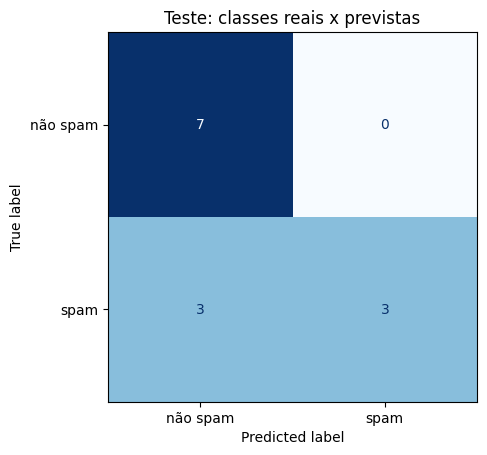

Condições aprendidas:
|--- um <= 0.50
|   |--- clique <= 0.50
|   |   |--- class: 0
|   |--- clique >  0.50
|   |   |--- class: 1
|--- um >  0.50
|   |--- class: 1



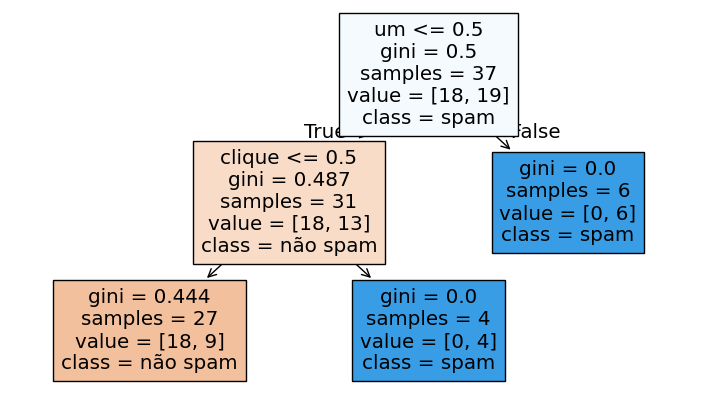

In [4]:
# Conversão dos textos em números: cada coluna é uma palavra e cada valor é a contagem dela na mensagem.
# O vetorizador aprende o vocabulário SOMENTE no treino (fit_transform) e apenas aplica no teste (transform).
vetorizador = CountVectorizer()
X_treino_vec = vetorizador.fit_transform(X_treino)
X_teste_vec = vetorizador.transform(X_teste)
nomes_atributos = list(vetorizador.get_feature_names_out())

# Inicialização do classificador de Árvore de Decisão limitando a profundidade a 2
modelo = DecisionTreeClassifier(max_depth=2, random_state=42)

# Treinamento do modelo usando o conjunto de treino (ajuste aos dados)
modelo.fit(X_treino_vec, y_treino)

# Geração de previsões utilizando os atributos do conjunto de teste
previsoes = modelo.predict(X_teste_vec)

# Cálculo e exibição da acurácia do modelo no conjunto de teste
print(f"Acurácia no teste: {accuracy_score(y_teste, previsoes):.1%}")

# Definição das classes (0 = não spam, 1 = spam) para ordenação da matriz de confusão
classes = [0, 1]
nomes_classes = ["não spam", "spam"]
matriz = confusion_matrix(y_teste, previsoes, labels=classes)

# Exibição da matriz de confusão em formato textual (linhas = real, colunas = previsto)
print(pd.DataFrame(matriz, index=nomes_classes, columns=nomes_classes))

# Exibição gráfica da matriz de confusão
ConfusionMatrixDisplay(matriz, display_labels=nomes_classes).plot(
    cmap="Blues", colorbar=False
)
plt.title("Teste: classes reais x previstas")
plt.show()

# Exibição das regras lógicas aprendidas pela árvore de decisão em formato texto
print("Condições aprendidas:")
print(export_text(modelo, feature_names=nomes_atributos))

# Plotagem gráfica da estrutura da árvore de decisão
plt.figure(figsize=(9, 5))
plot_tree(modelo, feature_names=nomes_atributos,
          class_names=nomes_classes, filled=True)
plt.show()
plt.show()

### Entendendo os Termos da Árvore de Decisão

Cada nó (caixa) na visualização da árvore contém três métricas que explicam como o algoritmo tomou suas decisões:

1. **Gini (Índice Gini):**
   * Mede a **impureza** ou mistura dos dados naquele nó. Varia de `0.0` (pureza total) a `0.5` (mistura máxima para duas classes).
   * **`gini = 0.0` (nós folha):** todas as mensagens que chegaram ali pertencem a uma única classe (spam ou não spam), ou seja, estão perfeitamente separadas.
   * **Nó raiz:** o gini fica próximo de `0.5`, porque o treino tem quase metade de spam e metade de não spam.

2. **Samples (Amostras):**
   * Indica o **número de mensagens** do conjunto de treino analisadas naquele nó.
   * O nó raiz começa com `37` amostras. Depois da primeira regra de divisão (por exemplo, `palavra <= 0.5`, que separa as mensagens que contêm uma palavra das que não contêm), cada nó filho recebe uma parte dessas 37 mensagens.

3. **Value (Valores por classe):**
   * Mostra a **distribuição exata** de mensagens em cada classe, no formato `[não spam, spam]`, seguindo a ordem crescente dos rótulos (0, 1).
   * Na raiz, o valor é aproximadamente metade para cada classe, porque o treino foi estratificado.
   * Em um nó folha com `value = [x, 0]`, todas as `x` mensagens são não spam. Em um com `value = [0, y]`, todas são spam.

**Interpretação:** como as classes foram construídas com separação simples e existem apenas quatro casos de teste, mesmo 100% de acurácia não demonstra eficácia em situações reais. A árvore mostra condições aprendidas; as regras de recomendação abaixo foram escritas por pessoas.

## 5. Base de conhecimento e motor de inferência
A previsão do modelo vira um fato (a mensagem é spam ou não spam). Outro fato, informado pelo usuário, é se o remetente é conhecido. O motor procura a regra compatível e apresenta a recomendação e a justificativa.

In [5]:
# Base de Conhecimento: regras do tipo SE (previsão do modelo E remetente) ENTÃO (recomendação)
# previsao: 1 = spam, 0 = não spam
regras = [
    {"id": "R1", "previsao": 1, "remetente_conhecido": False,
     "acao": "Apagar a mensagem e denunciá-la como spam."},
    {"id": "R2", "previsao": 1, "remetente_conhecido": True,
     "acao": "Confirmar com o remetente por outro canal; a conta dele pode ter sido invadida."},
    {"id": "R3", "previsao": 0, "remetente_conhecido": False,
     "acao": "Não clicar em links nem enviar dados antes de verificar quem é o remetente."},
    {"id": "R4", "previsao": 0, "remetente_conhecido": True,
     "acao": "Tratar como uma mensagem normal."}
]
nomes_classes = {0: "não spam", 1: "spam"}
# Motor de Inferência: recebe os fatos e busca a regra correspondente na base
def aplicar_regras(previsao, remetente_conhecido):
    for regra in regras:
        # Verifica se as condições da regra coincidem com os fatos fornecidos
        if (regra["previsao"] == previsao and
                regra["remetente_conhecido"] == remetente_conhecido):
            return {
                "previsao_modelo": nomes_classes[previsao],
                "regra": regra["id"],
                "recomendacao": regra["acao"],
                "explicacao": (
                    f"Previsão do modelo: {nomes_classes[previsao]}; "
                    f"remetente conhecido: {'sim' if remetente_conhecido else 'não'}."
                )
            }
    # Lança erro se nenhuma regra cobrir a combinação de fatos de entrada
    raise ValueError("Nenhuma regra compatível com os fatos.")
# Liga o modelo treinado ao motor: a previsão vira um fato para as regras
def classificar_mensagem(texto, remetente_conhecido):
    texto_vec = vetorizador.transform([texto])
    previsao = int(modelo.predict(texto_vec)[0])
    return aplicar_regras(previsao, remetente_conhecido)
# Exemplo de uso
resultado = classificar_mensagem(
    "Parabéns! Você ganhou um prêmio. Clique no link para receber.",
    remetente_conhecido=False
)
for chave, valor in resultado.items():
    print(f"{chave}: {valor}")

previsao_modelo: spam
regra: R1
recomendacao: Apagar a mensagem e denunciá-la como spam.
explicacao: Previsão do modelo: spam; remetente conhecido: não.


## 6. Integrar o modelo ao sistema especialista
A função valida os valores, realiza a previsão e aplica as regras. Valores fora dos intervalos observados no treino recebem um aviso, pois a previsão pode ser menos confiável.

In [6]:
# Integração: função que unifica o modelo de Machine Learning e o Sistema Especialista
def orientar_mensagem(texto, remetente_conhecido):
    # Validações dos dados de entrada
    if not isinstance(texto, str) or not texto.strip():
        raise ValueError("A mensagem deve ser um texto não vazio.")
    if not isinstance(remetente_conhecido, bool):
        raise ValueError("Remetente conhecido deve ser True ou False.")

    # Conversão do texto em contagens de palavras, usando o vocabulário aprendido no treino
    texto_vec = vetorizador.transform([texto])
    # 1. Classificação: previsão do modelo de Árvore de Decisão (0 = não spam, 1 = spam)
    previsao = int(modelo.predict(texto_vec)[0])
    # 2. Inferência: aplicação das regras do sistema especialista
    resultado = aplicar_regras(previsao, remetente_conhecido)
    # Verificação se a mensagem tem alguma palavra conhecida pelo modelo.
    # Se nenhuma palavra existe no vocabulário do treino, a previsão é pouco confiável.
    palavras = vetorizador.build_analyzer()(texto)
    conhecidas = [p for p in palavras if p in vetorizador.vocabulary_]
    fora = len(conhecidas) == 0
    # Aviso sobre a confiabilidade do resultado
    resultado["aviso"] = (
        "Nenhuma palavra da mensagem aparece no vocabulário do treino; previsão pouco confiável."
        if fora else "Exemplo didático; orientação sujeita a revisão humana."
    )
    return resultado
# Casos de teste (mensagens novas, não vistas no treinamento do modelo)
casos = [
    ("Parabéns! Você ganhou um prêmio. Clique no link para receber.", False),
    ("Seu cartão foi bloqueado. Confirme seus dados neste link.", True),
    ("Bom dia! Segue em anexo o relatório da reunião.", True),
    ("xyz qwerty asdf", False),
]
# Loop para classificar e aplicar as regras a cada caso
for i, (texto, remetente) in enumerate(casos, 1):
    print(f"\nCASO {i}: \"{texto}\"; remetente conhecido={remetente}")
    for campo, valor in orientar_mensagem(texto, remetente).items():
        print(f"{campo}: {valor}")


CASO 1: "Parabéns! Você ganhou um prêmio. Clique no link para receber."; remetente conhecido=False
previsao_modelo: spam
regra: R1
recomendacao: Apagar a mensagem e denunciá-la como spam.
explicacao: Previsão do modelo: spam; remetente conhecido: não.
aviso: Exemplo didático; orientação sujeita a revisão humana.

CASO 2: "Seu cartão foi bloqueado. Confirme seus dados neste link."; remetente conhecido=True
previsao_modelo: não spam
regra: R4
recomendacao: Tratar como uma mensagem normal.
explicacao: Previsão do modelo: não spam; remetente conhecido: sim.
aviso: Exemplo didático; orientação sujeita a revisão humana.

CASO 3: "Bom dia! Segue em anexo o relatório da reunião."; remetente conhecido=True
previsao_modelo: não spam
regra: R4
recomendacao: Tratar como uma mensagem normal.
explicacao: Previsão do modelo: não spam; remetente conhecido: sim.
aviso: Exemplo didático; orientação sujeita a revisão humana.

CASO 4: "xyz qwerty asdf"; remetente conhecido=False
previsao_modelo: não spam

## 7. Experimente uma consulta
Altere os três valores abaixo e execute novamente. Compare casos com a mesma previsão e diferentes respostas sobre dificuldade em lógica. Qual componente modifica a recomendação?

In [7]:
# Definição das variáveis de entrada para uma consulta simulada
texto = "Seu cartão foi bloqueado. Confirme seus dados neste link."
remetente_conhecido = True

# Execução da consulta chamando a função integradora do sistema
resultado = orientar_mensagem(texto, remetente_conhecido)

# Exibição detalhada de cada atributo retornado pelo motor de inferência
for campo, valor in resultado.items():
    print(f"{campo}: {valor}")

previsao_modelo: não spam
regra: R4
recomendacao: Tratar como uma mensagem normal.
explicacao: Previsão do modelo: não spam; remetente conhecido: sim.
aviso: Exemplo didático; orientação sujeita a revisão humana.


## Referências
- IBM. Guia de Aprendizado de Máquina: https://www.ibm.com/br-pt/think/machine-learning
- IBM. Aprendizado supervisionado: https://www.ibm.com/br-pt/think/topics/supervised-learning
- scikit-learn. DecisionTreeClassifier: https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeClassifier.html
- scikit-learn. train_test_split: https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html

- https://medium.com/@halfjourney/ai-is-already-making-images-of-things-that-never-happened-and-you-barely-notice-1a4f0cbe9bbe